# NN_L9_model_comparison

**Lecture 9 of Neural Networks and Deep Learning (NN), Elliptic Bitcoin transaction graph (Weber et al., 2019). Illicit-class F1 and PR-AUC on test steps 35-49 for logistic regression, MLP, GCN, GraphSAGE, GAT, random forest and random forest + GCN embeddings (mean and sd over seeds).**

Neural Networks and Deep Learning (NN), Lecture 9 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L9/NN_L9_model_comparison/NN_L9_model_comparison.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Mean and standard deviation over the runs of each model.

F1, random forest = 0.808   [models.rf.f1]
F1, GCN = 0.447   [models.gcn.f1]
PR-AUC, GCN = 0.442   [models.gcn.ap]
PR-AUC, MLP = 0.361   [models.mlp.ap]


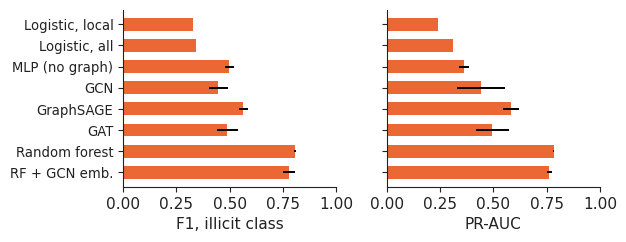

In [3]:
m = pd.read_csv(REPO + 'lectures/L9/results/' + 'model_metrics.csv')
g = m.groupby('model').agg(['mean', 'std'])
show('models.rf.f1', 'F1, random forest', round(float(g.loc['rf', ('f1', 'mean')]), 3))
show('models.gcn.f1', 'F1, GCN', round(float(g.loc['gcn', ('f1', 'mean')]), 3))
show('models.gcn.ap', 'PR-AUC, GCN', round(float(g.loc['gcn', ('ap', 'mean')]), 3))
show('models.mlp.ap', 'PR-AUC, MLP', round(float(g.loc['mlp', ('ap', 'mean')]), 3))
order = ['lr_local', 'lr_all', 'mlp', 'gcn', 'sage', 'gat', 'rf', 'rf_emb']
names = ['Logistic, local', 'Logistic, all', 'MLP (no graph)', 'GCN', 'GraphSAGE', 'GAT', 'Random forest', 'RF + GCN emb.']
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.9), sharey=True)
for ax, k, xl in [(axs[0], 'f1', 'F1, illicit class'), (axs[1], 'ap', 'PR-AUC')]:
    ax.barh(range(8), [g.loc[o, (k, 'mean')] for o in order], xerr=[np.nan_to_num(g.loc[o, (k, 'std')]) for o in order], color=PAL['model'], height=0.6)
    ax.set_xlabel(xl); ax.set_xlim(0, 1)
axs[0].set_yticks(range(8)); axs[0].set_yticklabels(names, fontsize=9.5); axs[0].invert_yaxis()
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('model_comparison.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()